# Create a World

Build a world with pyotter: load a map template, look at its road graph, forecast its hazards, roll the hazards that occur in one run, then save and reload it.

In [1]:
from pathlib import Path

from pyotter import Visualize, World
from pyotter.core import WorldHazardLibrary, WorldRoadGraph
from pyotter.modules.world import WorldHazardSpawns

OUTPUT = Path("runs")
OUTPUT.mkdir(exist_ok=True)

## Hazard Library

An **event** happens at a moment, at a place. It is assigned to segments, and its probability is the chance per second that one starts there.

A **condition** holds over the whole world for the whole run. It is forecast once, with a chance of being present and a severity.

In [2]:
hazards = WorldHazardLibrary()

for hazard in hazards:
    print(f"{hazard.id:16} {hazard.kind.value:10} {hazard.description}")

pedestrian       event      A pedestrian is on or entering the roadway
low_visibility   condition  Detection range is reduced
wet_road         condition  Tire friction is reduced


## Road Graph

The road graph is the map as a set of segments. A segment is one directed lane between two points where lanes branch or join. With no hazard forecast yet, a road graph is called a template.

In [3]:
wrg = WorldRoadGraph.from_template("town10")

segments = wrg.get_segments()
print(f"{wrg.map_name}: {len(segments)} segments, {len(wrg.spawn_points)} spawn points")

Town10HD_Opt: 168 segments, 155 spawn points


`Visualize.topology` returns a matplotlib `Figure` with axes in meters. `LABEL_SEGMENTS` prints each segment ID along its lane. The labelled figure is larger, so open or zoom the image to read the IDs. `SHOW_JUNCTIONS` outlines each junction's bounding box and tags it with its ID.

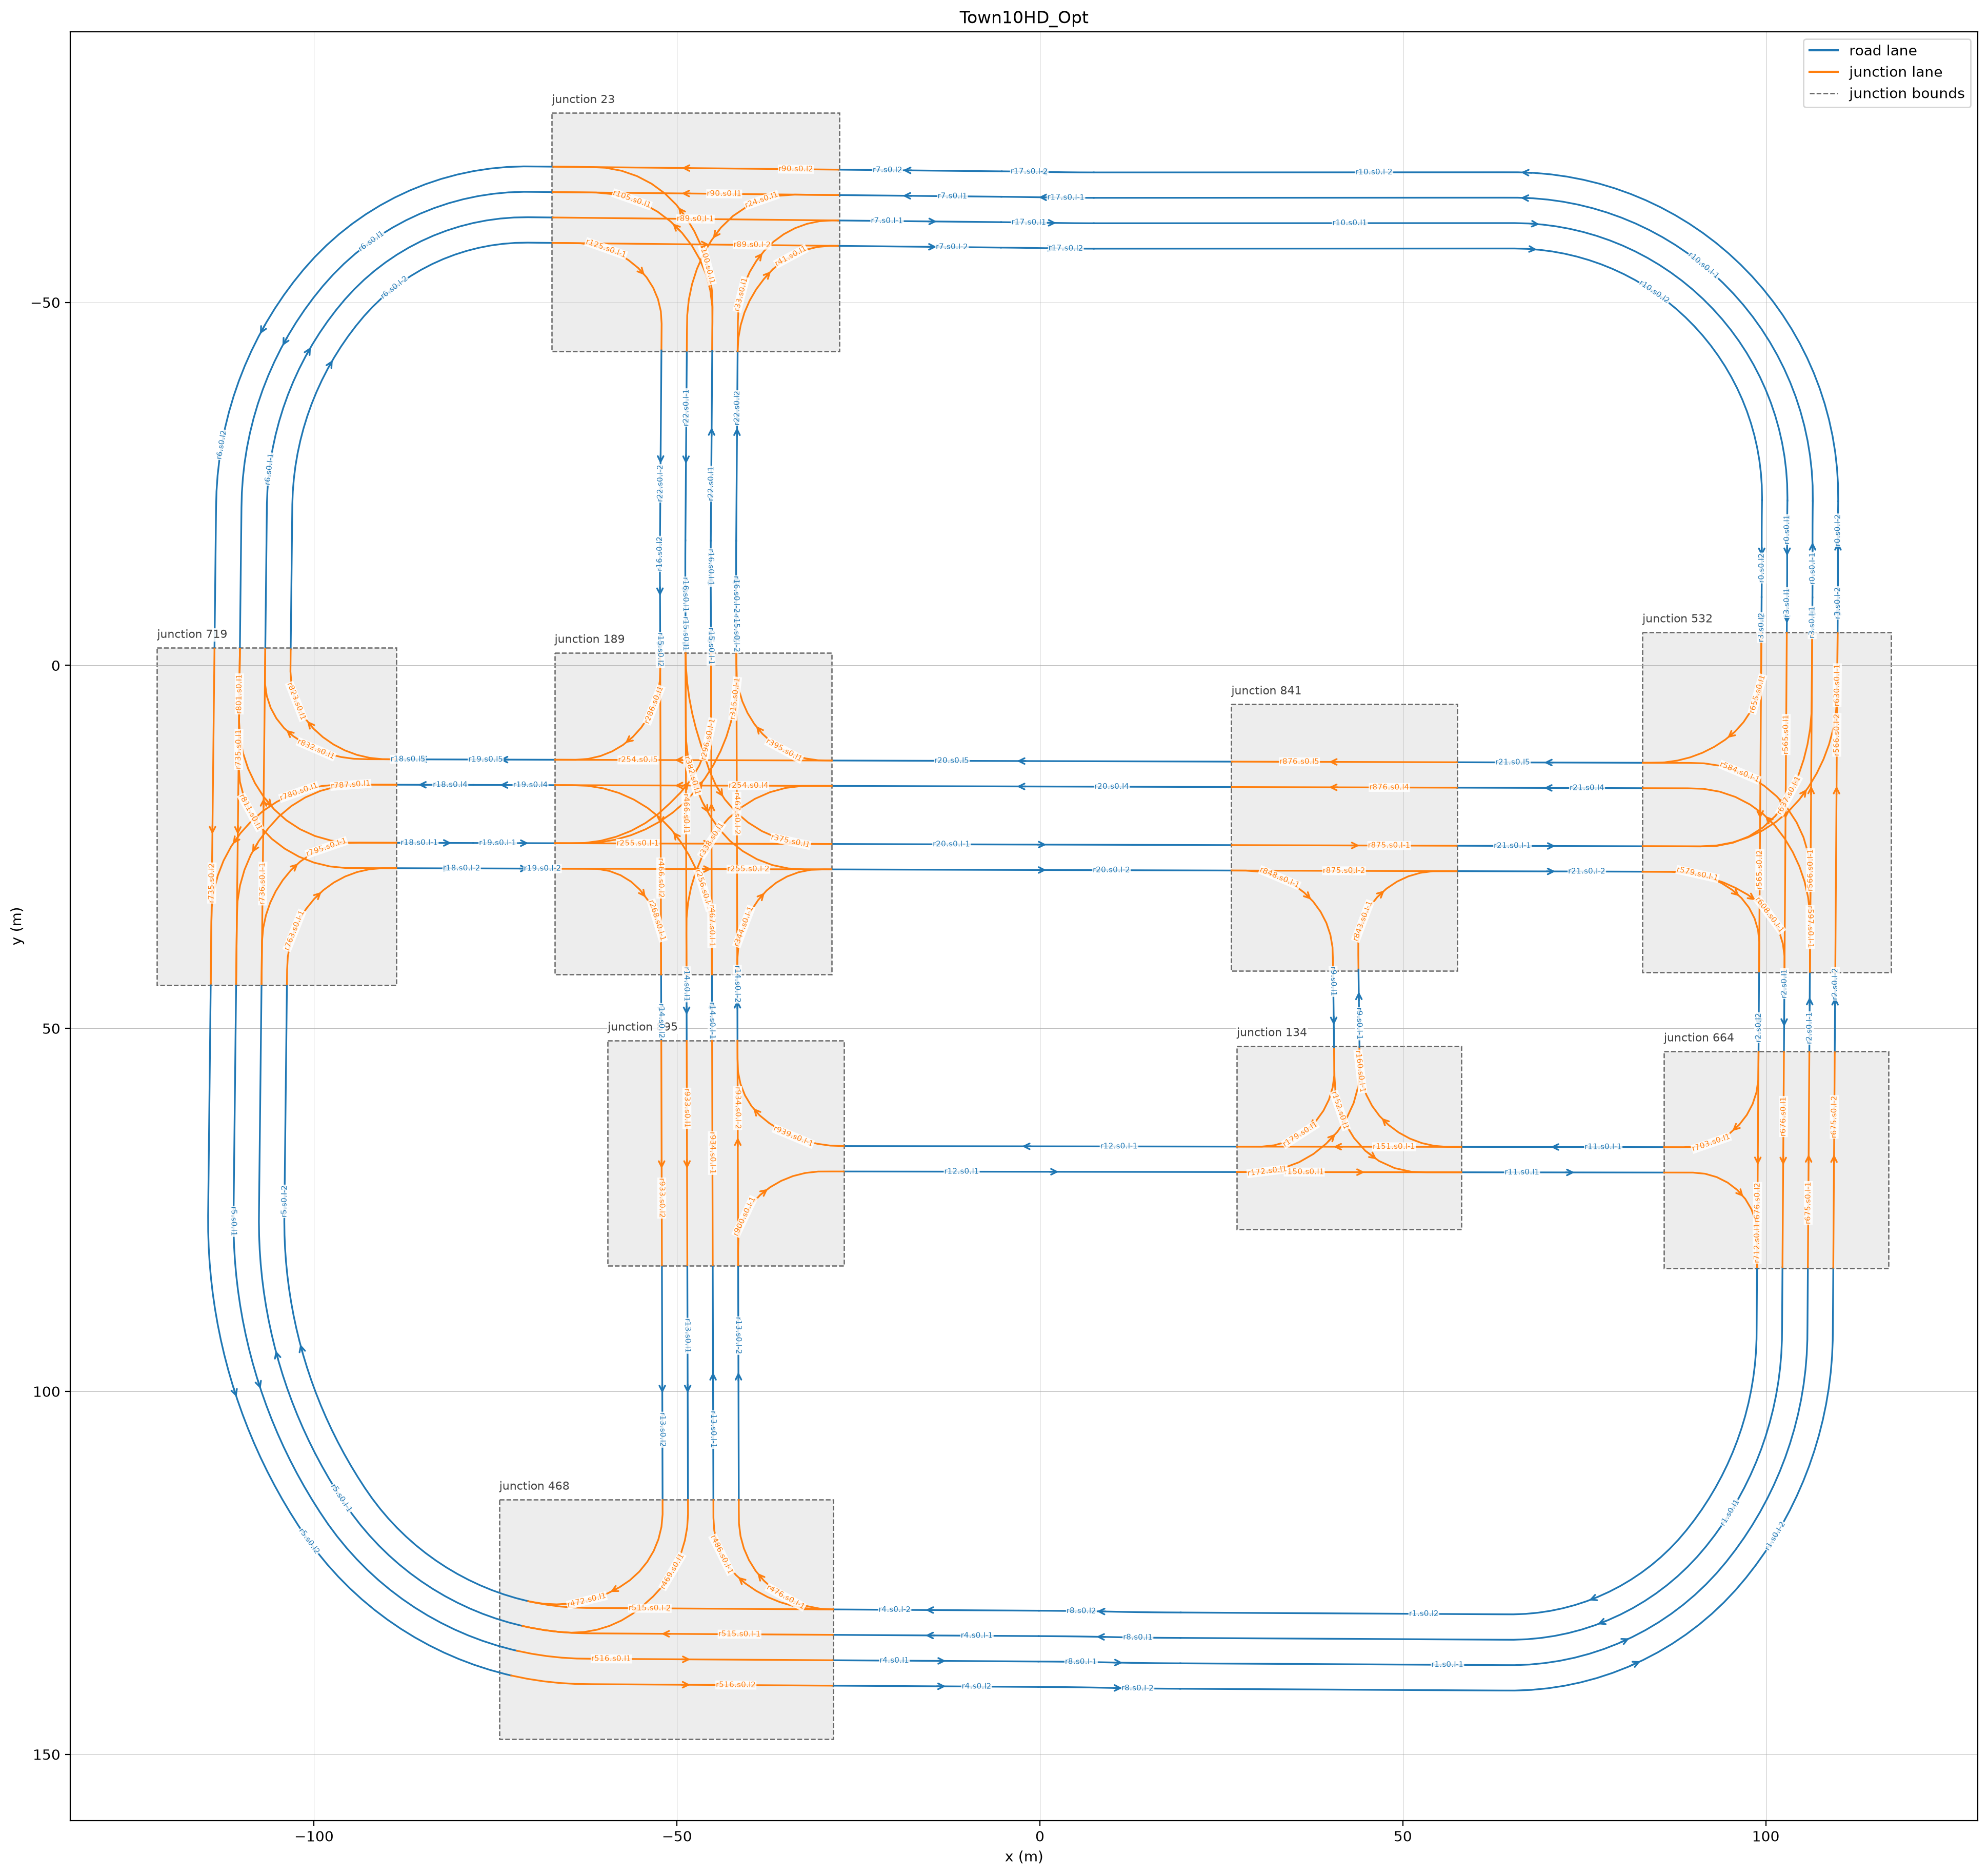

In [4]:
LABEL_SEGMENTS = True
SHOW_JUNCTIONS = True

figure = Visualize.topology(wrg, label_segments=LABEL_SEGMENTS, show_junctions=SHOW_JUNCTIONS)
figure.savefig(OUTPUT / "town10-topology.png", bbox_inches="tight")

## Segments

A segment's ID comes from the map's own numbers for its road, lane section and lane.

In [5]:
segment = wrg.get_segment("r296.s0.l-1")

print(f"{segment.id}: {segment.length_m:.1f} m, limit {segment.speed_limit_kmh:g} km/h")
print("leads to:", ", ".join(segment.successors))
print("midpoint (x, y, z):", tuple(round(v, 2) for v in segment.point_at(segment.length_m / 2)))

r296.s0.l-1: 39.7 m, limit 30 km/h
leads to: r15.s0.l-1
midpoint (x, y, z): (-49.24, 17.19, 0.0)


## Junctions

A junction is an intersection declared by the map. Each segment inside one carries its `junction_id`, and the junction has a bounding box in meters.

In [6]:
print(f"{segment.id} is in junction {segment.junction_id}")

for junction in wrg.get_junctions():
    lanes = wrg.segments_in_junction(junction.id)
    print(f"junction {junction.id:4}: {len(lanes):2} lanes, center ({junction.x:7.1f}, {junction.y:7.1f}), "
          f"{2 * junction.extent_x:.0f} m x {2 * junction.extent_y:.0f} m")

r296.s0.l-1 is in junction 189
junction   23: 10 lanes, center (  -47.4,   -59.7), 40 m x 33 m
junction  134:  6 lanes, center (   42.6,    65.1), 31 m x 25 m
junction  189: 18 lanes, center (  -47.8,    20.4), 38 m x 44 m
junction  468:  8 lanes, center (  -51.5,   131.4), 46 m x 33 m
junction  532: 11 lanes, center (  100.1,    18.9), 34 m x 47 m
junction  664:  6 lanes, center (  101.4,    68.1), 31 m x 30 m
junction  719: 11 lanes, center ( -105.1,    20.8), 33 m x 46 m
junction  841:  6 lanes, center (   41.9,    23.7), 31 m x 37 m
junction  895:  6 lanes, center (  -43.3,    67.2), 33 m x 31 m


## Forecast the Hazards

### Events

Events are assigned per segment. Each segment holds one probability per event, and assigning the same event again replaces its value.

In [7]:
segment.assign_hazard_probability([
    (hazards.pedestrian, 0.03),  # chance per second that one starts
])

segment.hazard_probabilities

[HazardProbability(hazard_id='pedestrian', probability=0.03),
 HazardProbability(hazard_id='wet_road', probability=0.4)]

Assign across groups of segments by filtering the graph, for example every lane of a junction.

In [8]:
for lane in wrg.segments_in_junction(189):
    lane.assign_hazard_probability([(hazards.pedestrian, 0.03)])
for lane in wrg.segments_in_junction(841):
    lane.assign_hazard_probability([(hazards.pedestrian, 0.01)])

print("events assigned:", ", ".join(sorted(wrg.event_ids())))

hazards assigned: low_visibility, pedestrian, wet_road


### Conditions

A condition is forecast once for the whole world, with three numbers from 0 to 1:

- `probability`: the chance that the condition is present in a run.
- `severity`: how strong it is when present. Pass a number, or `"low"`, `"mid"` or `"high"`.
- `variability`: how far the severity of an actual run can land from that value, in either direction.

A high severity with a high chance and little variability is nearly certain to be severe. With a mid severity and wide variability, a run can turn out mild or severe.

In [ ]:
wrg.set_condition(hazards.wet_road, probability=0.9, severity="high", variability=0.1)
wrg.set_condition(hazards.low_visibility, probability=0.5, severity="mid", variability=0.4)

for forecast in wrg.conditions.values():
    low, high = forecast.severity_range()
    print(f"{forecast.hazard_id:15} {forecast.probability:.0%} chance, severity {low:.2f} to {high:.2f}")

### Low Sun

`low_visibility` stands for rain or fog, which is the same in every direction. The low sun is different: it only matters when driving toward it, and only when the air is clear. Set a time of day and the world works it out:

- The time gives the sun's height and direction. A sun near the horizon has a low-sun factor near 1. For a high sun, or at night, the factor is 0.
- Rain or fog scales the glare down, because it already hides the sun. Full fog leaves no glare.
- Each lane is exposed by how directly it heads toward the sun, averaged along its length.

The result is a strength from 0 to 1: the share of visibility lost when facing the sun. Turning that into a distance is the driver module's job.

In [ ]:
from pyotter.core.utilities.sun import glare_strength, segment_sun_exposure, sun_position

wrg.set_time_of_day(17.5)

altitude, azimuth = sun_position(wrg.time_of_day_h)
print(f"sun at 17:30: {altitude:.1f} degrees above the horizon, toward {azimuth:.1f} degrees in the map frame")
for fog in (0.0, 0.5, 1.0):
    print(f"  rain or fog severity {fog:.1f} -> facing the sun loses {glare_strength(wrg.time_of_day_h, fog):.2f}")

for sid in ("r20.s0.l4", "r20.s0.l-1"):
    print(f"{sid}: exposure {segment_sun_exposure(wrg.get_segment(sid), azimuth):.2f}")

`Visualize.hazards` draws the forecast, one map per hazard, each with its own color and scale:

- **pedestrian** shades each segment by its chance per second.
- **low_visibility** shades each lane by its expected visibility loss: the rain or fog everywhere, plus the low sun on the lanes that head toward it. The arrow points to the sun.
- **wet_road** shades the whole world by expected severity.

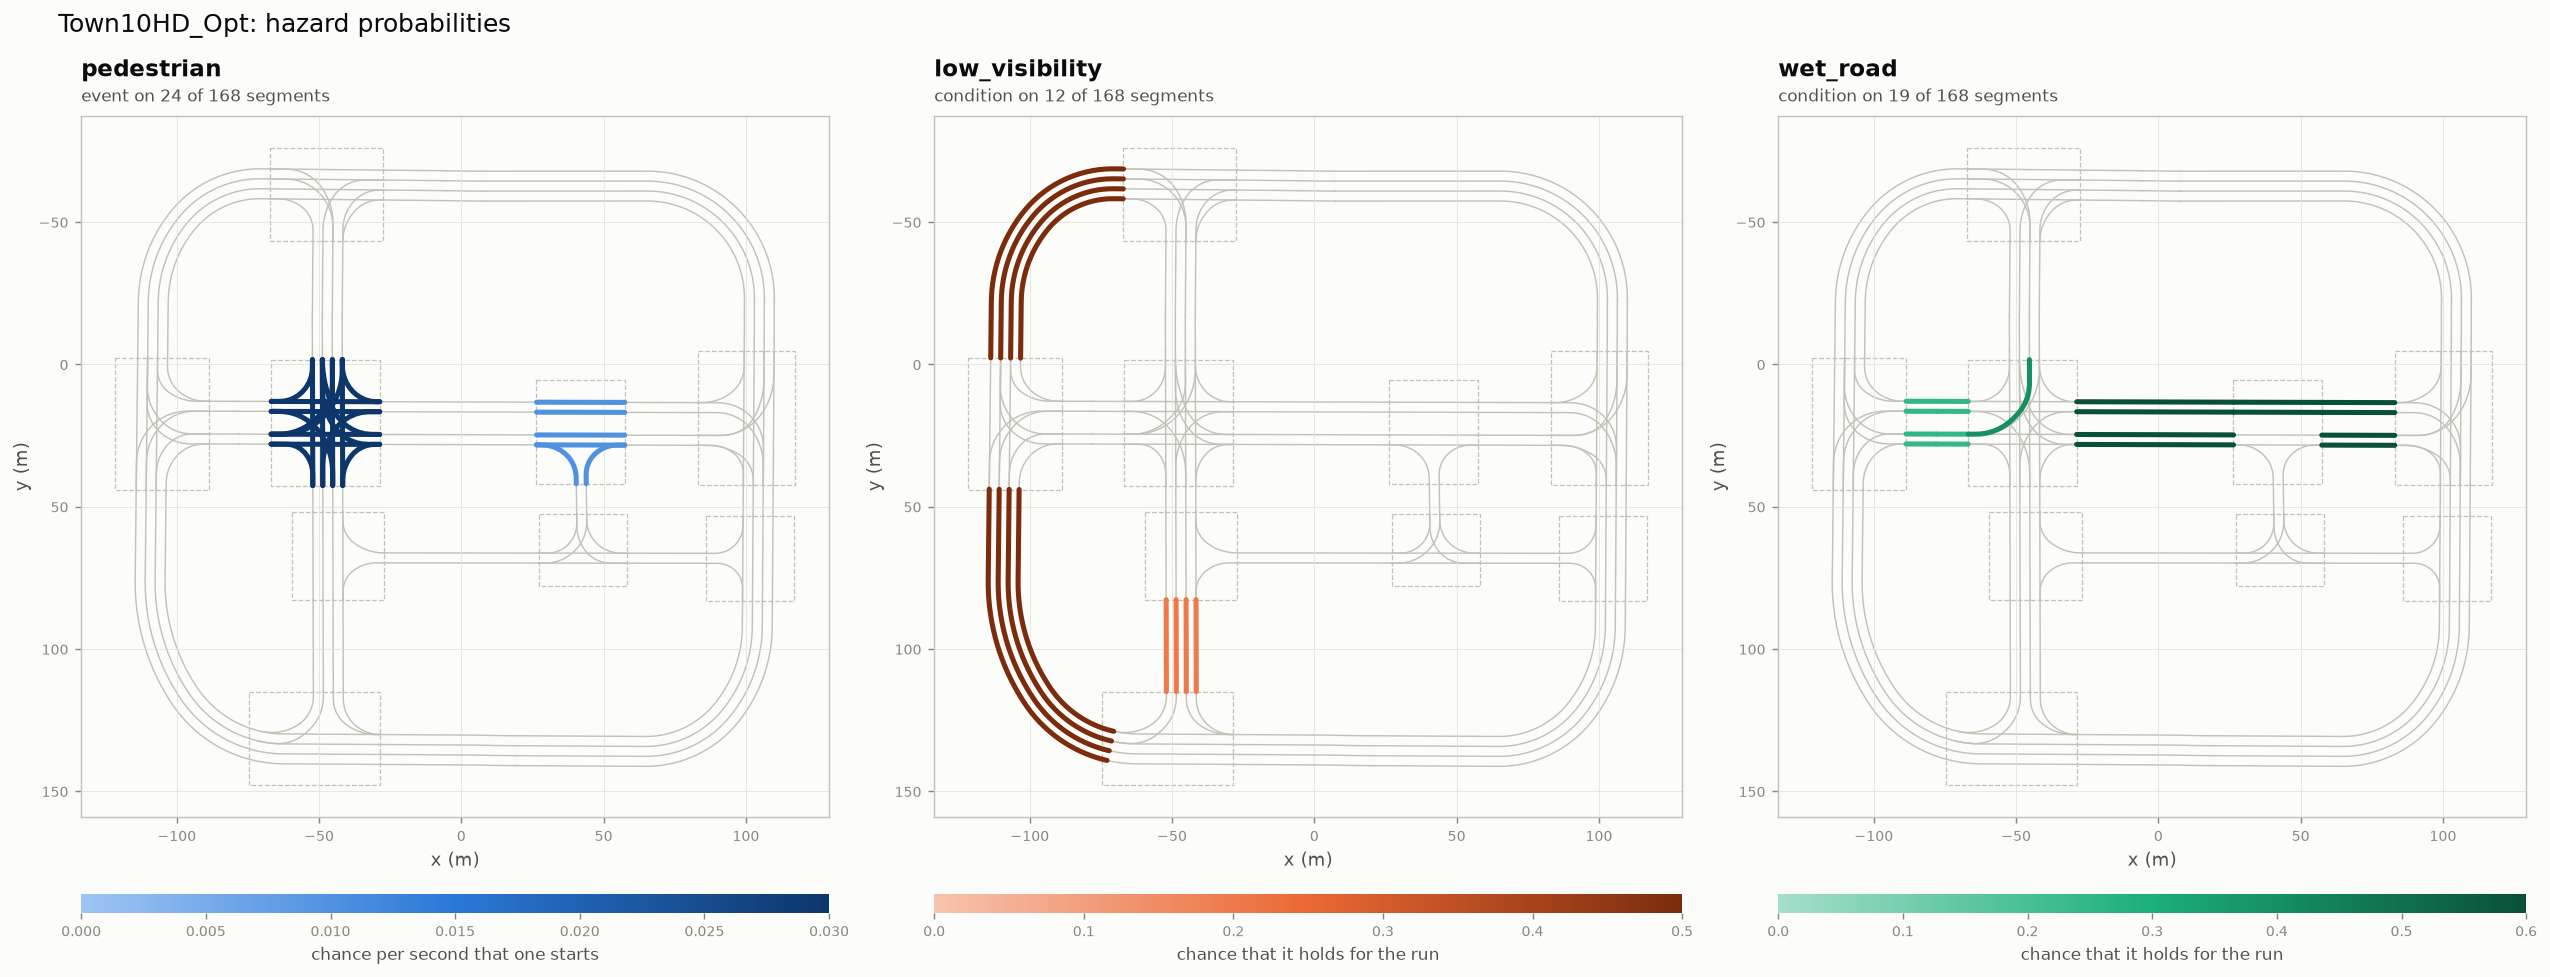

In [9]:
figure = Visualize.hazards(wrg, hazards, show_junctions=SHOW_JUNCTIONS)
figure.savefig(OUTPUT / "town10-hazards.png", bbox_inches="tight")

## Roll the Hazards

The forecast says what could happen. `roll_hazards` decides what does happen in one run, from a seed:

- A **condition** is drawn once: whether it is present, and at what severity within its range.
- An **event** is drawn once per second of simulation time on each segment. Each success is one start, at a drawn moment within that second and a drawn point along the segment.
- The **sun's glare** follows from the time of day and the rolled rain or fog.

The result is a separate `WorldHazardSpawns` object, called the spawns below. It is not stored on the road graph, so a planner that reads the graph sees the forecast only.

In [10]:
SEED = 1227
DURATION_S = 120

spawns = World.roll_hazards(wrg, hazards, seed=SEED, duration_s=DURATION_S)

for condition in spawns.conditions:
    print(f"{condition.hazard_id}: severity {condition.severity:.2f} ({condition.level})")
print(f"sun: facing it loses {spawns.sun.strength:.2f}")
print(f"{len(spawns.events)} event starts in {spawns.duration_s:g} s; first: {spawns.events[0]}")

16 conditions and 60 event starts in 120 s
first condition: ConditionSpawn(hazard_id='low_visibility', segment_id='r13.s0.l2')
first event:     EventSpawn(hazard_id='pedestrian', position=SegmentPosition(segment_id='r382.s0.l1', offset_m=33.68811056851628), start_s=1.4804045680191469)


The same world, seed and duration always give the same spawns. Other seeds give other runs of the same world: a condition with a low chance is often absent, and one with wide variability lands at different severities.

In [11]:
again = World.roll_hazards(wrg, hazards, seed=SEED, duration_s=DURATION_S)
print("same seed, same spawns:", again == spawns)

print("\nother seeds, same world:")
for seed in range(SEED + 1, SEED + 6):
    other = World.roll_hazards(wrg, hazards, seed=seed, duration_s=DURATION_S)
    wet, fog = other.condition_severity(hazards.wet_road), other.condition_severity(hazards.low_visibility)
    print(f"  seed {seed}: wet road {wet:.2f}, low visibility {fog:.2f}, sun glare {other.sun.strength:.2f}, "
          f"{len(other.events)} pedestrian starts")

same seed, same spawns:      True
another seed, same spawns:   False


`Visualize.spawns` draws the roll with the same three maps. Each dot on the pedestrian map is one start, and the strip at the bottom shows when each one starts. The condition maps show this run's severity, and the visibility map adds the sun's glare lane by lane.

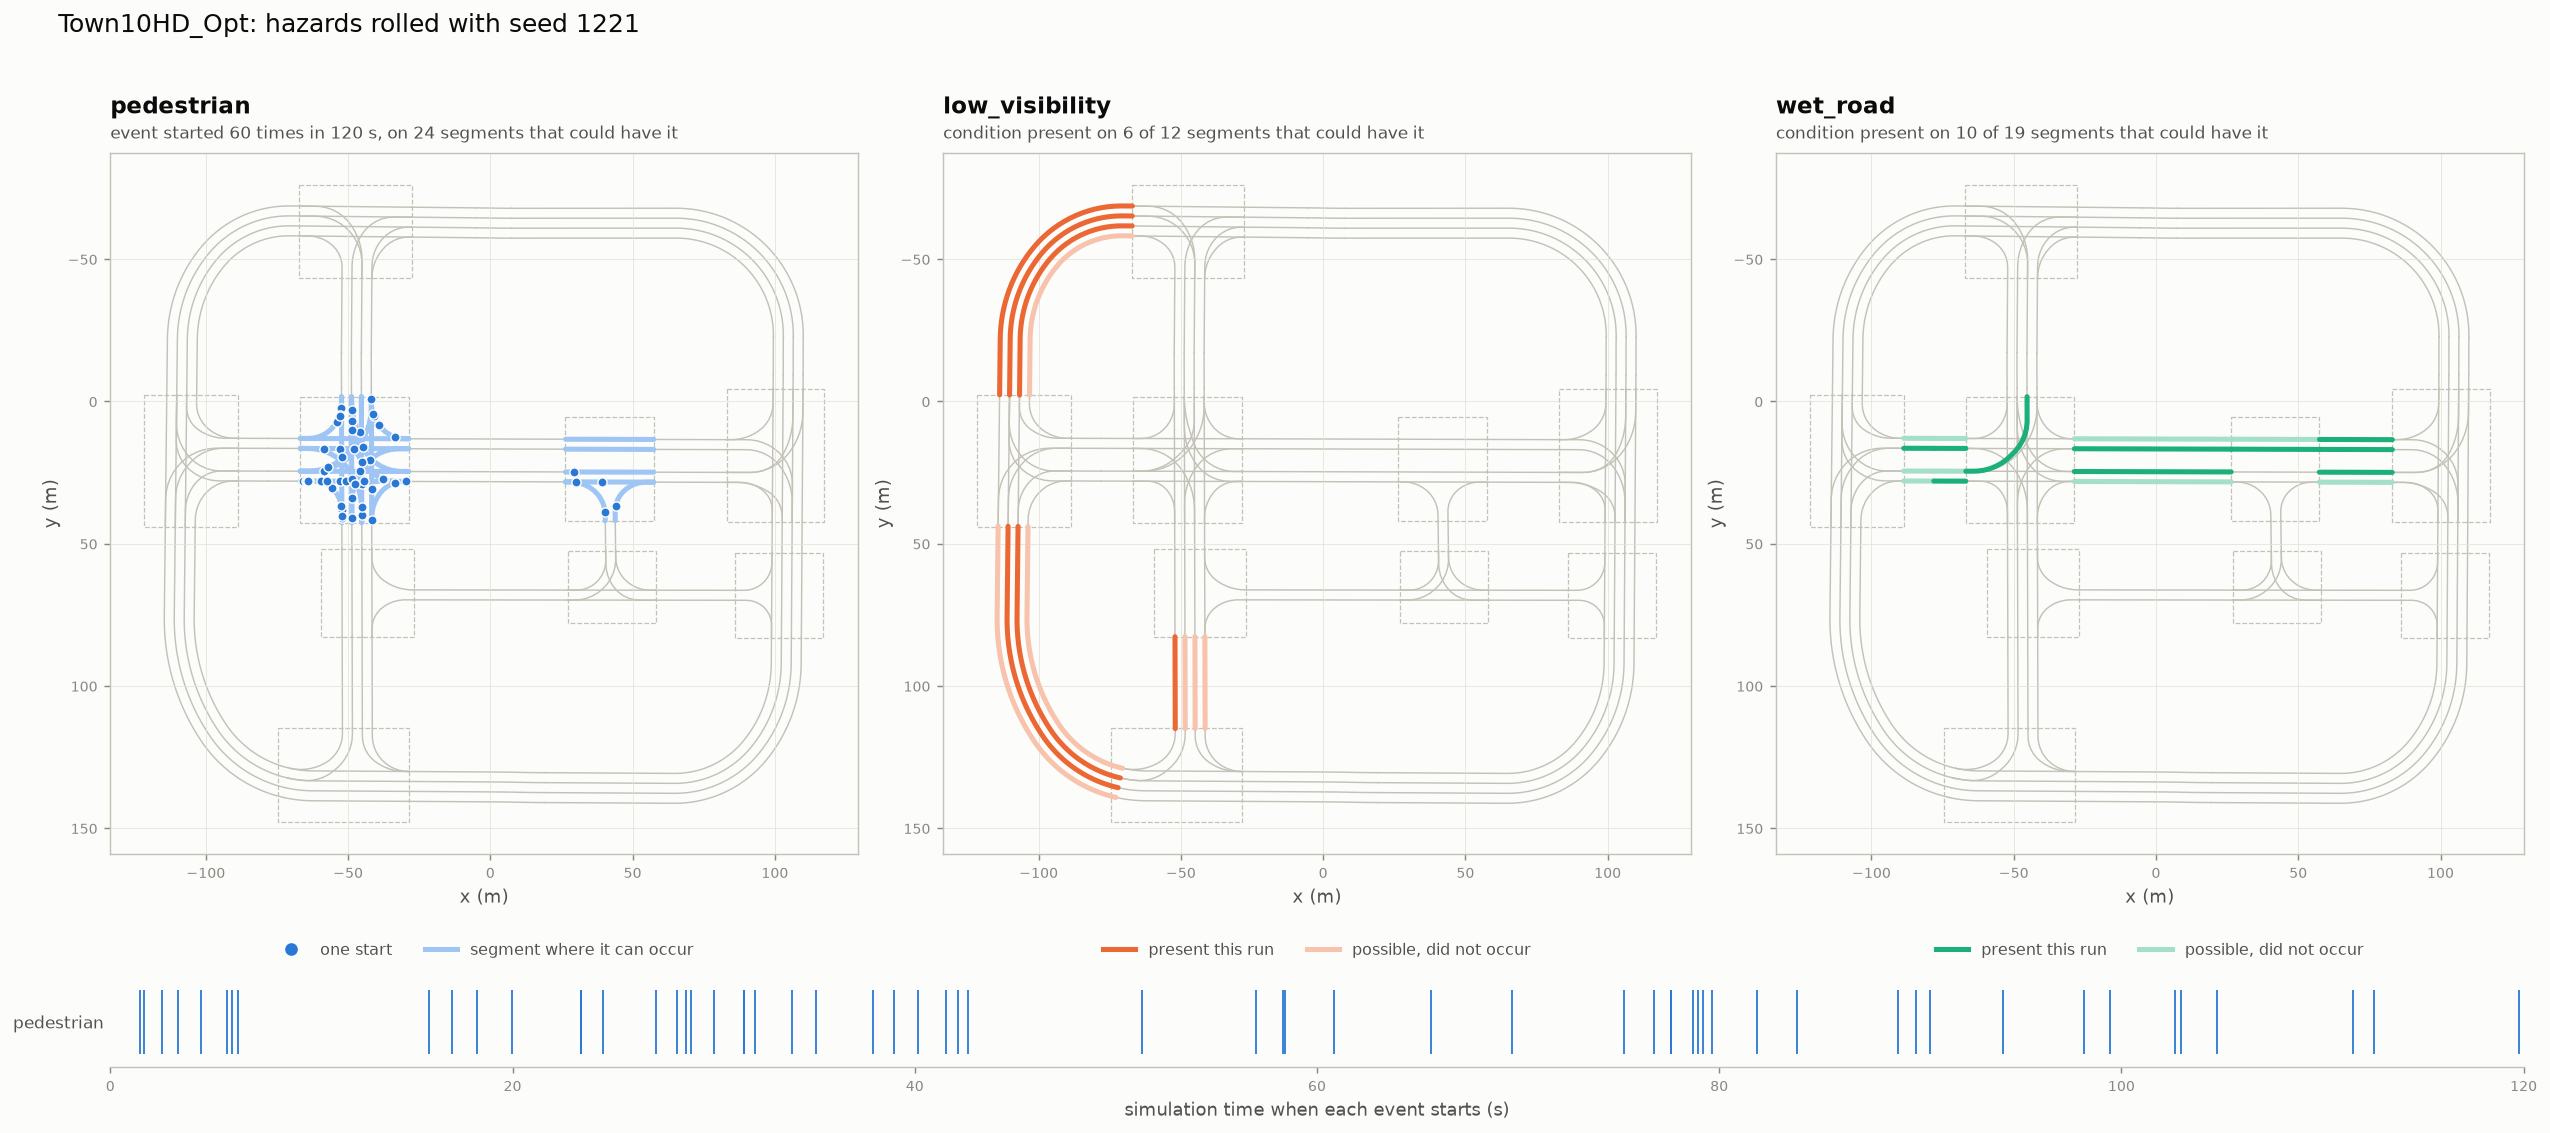

In [12]:
figure = Visualize.spawns(wrg, hazards, spawns, show_junctions=SHOW_JUNCTIONS)
figure.savefig(OUTPUT / "town10-spawns.png", bbox_inches="tight")

## Save and Load

In [13]:
path = OUTPUT / "town10-world.json.gz"
wrg.save(path)

wrg = WorldRoadGraph.load(path)
for item in wrg.get_segment("r296.s0.l-1").hazard_probabilities:
    print(f"{item.hazard_id} ({hazards.get(item.hazard_id).kind.value}): {item.probability}")

spawns_path = OUTPUT / f"town10-spawns-seed{SEED}.json.gz"
spawns.save(spawns_path)
print("spawns reload unchanged:", WorldHazardSpawns.load(spawns_path) == spawns)

pedestrian (event): 0.03
wet_road (condition): 0.4
spawns reload unchanged: True
